## Setup

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from google.colab import files

print(tf.__version__, sklearn.__version__)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

2.21.0 1.6.1


## 1. Load the processed data

In [2]:
# 1. LOAD THE PROCESSED DATA
# (the three split files from the preprocessing notebook)

base_url = "https://raw.githubusercontent.com/Group-22-AI-ML/medical-diagnosis-network/main/Model/Preprocessing/"

train = pd.read_csv(base_url + "train.csv")
val = pd.read_csv(base_url + "validation.csv")
test = pd.read_csv(base_url + "test.csv")

X_train = train.drop("class", axis=1)
y_train = train["class"].values

X_val = val.drop("class", axis=1)
y_val = val["class"].values

X_test = test.drop("class", axis=1)
y_test = test["class"].values

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Xtr, Xva, Xte = (d.values.astype("float32") for d in (X_train, X_val, X_test))

Train: (364, 9)
Validation: (78, 9)
Test: (78, 9)


In [3]:
print(list(X_train.columns))

['age', 'polyuria', 'polydipsia', 'sudden_weight_loss', 'weakness', 'polyphagia', 'genital_thrush', 'visual_blurring', 'obesity']


# 5. Experimentation Function

In [4]:
experiment_results = []

In [5]:
def run_experiment(
    X_train,
    y_train,
    X_val,
    y_val,
    hidden_layers=[16, 8],
    dropout_rate=0.0,
    learning_rate=0.001,
    batch_size=32,
    patience=10,
    experiment_name="Experiment",
    seed=42
):

    keras.utils.set_random_seed(seed)
    model = keras.Sequential()
    model.add(layers.Input(shape=(X_train.shape[1],)))

    model.add(layers.Dense(hidden_layers[0], activation="relu",
        )
    )
    if dropout_rate > 0:
        model.add(layers.Dropout(dropout_rate))

    # Add any additional hidden layers
    for units in hidden_layers[1:]:
        model.add(
            layers.Dense(
                units,
                activation="relu"
            )
        )

        if dropout_rate > 0:
            model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(1, activation="sigmoid"))

    optimizer = keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=patience,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=150,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0
    )

    probabilities = model.predict(
        X_val,
        verbose=0
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        y_val,
        predictions
    )

    precision = precision_score(
        y_val,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        predictions,
        zero_division=0
    )

    cm = confusion_matrix(
        y_val,
        predictions
    )

    TN, FP, FN, TP = cm.ravel()

    experiment_results.append({
        "Experiment": experiment_name,
        "Architecture": str(hidden_layers),
        "Dropout": dropout_rate,
        "Learning Rate": learning_rate,
        "Batch Size": batch_size,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Confusion Matrix": cm
    })

    print("Experiment:", experiment_name)
    print("Architecture:", hidden_layers)
    print("Dropout:", dropout_rate)
    print("Learning Rate:", learning_rate)
    print("Batch Size:", batch_size)

    print("\nValidation Results")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")

    print("\nConfusion Matrix")
    print(cm)

    print("\nConfusion Matrix Breakdown")
    print(f"True Negatives  (TN): {TN}")
    print(f"False Positives (FP): {FP}")
    print(f"False Negatives (FN): {FN}")
    print(f"True Positives  (TP): {TP}")

    # 8. Return everything we need later
    return {
        "model": model,
        "history": history,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "confusion_matrix": cm
    }

# 6. Architechture Tuning

6.1 Deeper Experiment + DropOut

In [6]:
dropout_01_result = run_experiment(
    X_train,
    y_train,
    X_val,
    y_val,
    hidden_layers=[32, 16, 8],
    dropout_rate=0.1,
    learning_rate=0.001,
    batch_size=32,
    experiment_name="Dropout 0.1"
)

Restoring model weights from the end of the best epoch: 144.
Experiment: Dropout 0.1
Architecture: [32, 16, 8]
Dropout: 0.1
Learning Rate: 0.001
Batch Size: 32

Validation Results
Accuracy : 0.9744
Precision: 1.0000
Recall   : 0.9592
F1-score : 0.9792

Confusion Matrix
[[29  0]
 [ 2 47]]

Confusion Matrix Breakdown
True Negatives  (TN): 29
False Positives (FP): 0
False Negatives (FN): 2
True Positives  (TP): 47


In [7]:
deeper_dropout_result = run_experiment(
    X_train,
    y_train,
    X_val,
    y_val,
    hidden_layers=[32, 16, 8],
    dropout_rate=0.2,
    learning_rate=0.001,
    batch_size=32,
    experiment_name="Dropout 0.2"
)

Epoch 102: early stopping
Restoring model weights from the end of the best epoch: 92.
Experiment: Dropout 0.2
Architecture: [32, 16, 8]
Dropout: 0.2
Learning Rate: 0.001
Batch Size: 32

Validation Results
Accuracy : 0.9359
Precision: 1.0000
Recall   : 0.8980
F1-score : 0.9462

Confusion Matrix
[[29  0]
 [ 5 44]]

Confusion Matrix Breakdown
True Negatives  (TN): 29
False Positives (FP): 0
False Negatives (FN): 5
True Positives  (TP): 44


In [8]:
deeper_dropout_03_result = run_experiment(
    X_train,
    y_train,
    X_val,
    y_val,
    hidden_layers=[32, 16, 8],
    dropout_rate=0.3,
    learning_rate=0.001,
    batch_size=32,
    experiment_name="Dropout 0.3"
)

Epoch 76: early stopping
Restoring model weights from the end of the best epoch: 66.


Experiment: Dropout 0.3
Architecture: [32, 16, 8]
Dropout: 0.3
Learning Rate: 0.001
Batch Size: 32

Validation Results
Accuracy : 0.9103
Precision: 1.0000
Recall   : 0.8571
F1-score : 0.9231

Confusion Matrix
[[29  0]
 [ 7 42]]

Confusion Matrix Breakdown
True Negatives  (TN): 29
False Positives (FP): 0
False Negatives (FN): 7
True Positives  (TP): 42


In [9]:
lr_0005_result = run_experiment(
    X_train,
    y_train,
    X_val,
    y_val,
    hidden_layers=[32, 16, 8],
    dropout_rate=0.2,
    learning_rate=0.0005,
    batch_size=32,
    experiment_name="LR 0.0005"
)

Epoch 105: early stopping
Restoring model weights from the end of the best epoch: 95.
Experiment: LR 0.0005
Architecture: [32, 16, 8]
Dropout: 0.2
Learning Rate: 0.0005
Batch Size: 32

Validation Results
Accuracy : 0.9103
Precision: 1.0000
Recall   : 0.8571
F1-score : 0.9231

Confusion Matrix
[[29  0]
 [ 7 42]]

Confusion Matrix Breakdown
True Negatives  (TN): 29
False Positives (FP): 0
False Negatives (FN): 7
True Positives  (TP): 42


In [10]:
lr_001_result = run_experiment(
    X_train,
    y_train,
    X_val,
    y_val,
    hidden_layers=[32, 16, 8],
    dropout_rate=0.2,
    learning_rate=0.01,
    batch_size=32,
    experiment_name="LR 0.01"
)

Epoch 54: early stopping
Restoring model weights from the end of the best epoch: 44.
Experiment: LR 0.01
Architecture: [32, 16, 8]
Dropout: 0.2
Learning Rate: 0.01
Batch Size: 32

Validation Results
Accuracy : 0.9487
Precision: 1.0000
Recall   : 0.9184
F1-score : 0.9574

Confusion Matrix
[[29  0]
 [ 4 45]]

Confusion Matrix Breakdown
True Negatives  (TN): 29
False Positives (FP): 0
False Negatives (FN): 4
True Positives  (TP): 45


In [11]:
batch_16_result = run_experiment(
    X_train,
    y_train,
    X_val,
    y_val,
    hidden_layers=[32, 16, 8],
    dropout_rate=0.2,
    learning_rate=0.001,
    batch_size=16,
    experiment_name="Batch-size 16"
)

Epoch 130: early stopping
Restoring model weights from the end of the best epoch: 120.
Experiment: Batch-size 16
Architecture: [32, 16, 8]
Dropout: 0.2
Learning Rate: 0.001
Batch Size: 16

Validation Results
Accuracy : 0.9744
Precision: 1.0000
Recall   : 0.9592
F1-score : 0.9792

Confusion Matrix
[[29  0]
 [ 2 47]]

Confusion Matrix Breakdown
True Negatives  (TN): 29
False Positives (FP): 0
False Negatives (FN): 2
True Positives  (TP): 47


In [12]:
batch_64_result = run_experiment(
    X_train,
    y_train,
    X_val,
    y_val,
    hidden_layers=[32, 16, 8],
    dropout_rate=0.2,
    learning_rate=0.001,
    batch_size=64,
    experiment_name="Batch-size 64"
)

Epoch 134: early stopping
Restoring model weights from the end of the best epoch: 124.
Experiment: Batch-size 64
Architecture: [32, 16, 8]
Dropout: 0.2
Learning Rate: 0.001
Batch Size: 64

Validation Results
Accuracy : 0.9359
Precision: 1.0000
Recall   : 0.8980
F1-score : 0.9462

Confusion Matrix
[[29  0]
 [ 5 44]]

Confusion Matrix Breakdown
True Negatives  (TN): 29
False Positives (FP): 0
False Negatives (FN): 5
True Positives  (TP): 44


# Summary of Experiments

In [13]:
if not experiment_results:
    experiments = [
        ("Dropout 0.1", globals().get("dropout_01_result")),
        ("Dropout 0.2", globals().get("deeper_dropout_result")),
        ("Dropout 0.3", globals().get("deeper_dropout_03_result")),
        ("LR 0.0005", globals().get("lr_0005_result")),
        ("LR 0.01", globals().get("lr_001_result")),
        ("Batch-size 16", globals().get("batch_16_result")),
        ("Batch-size 64", globals().get("batch_64_result"))
    ]

    for name, res in experiments:
        if res:
            experiment_results.append({
                "Experiment": name,
                "Architecture": str(res["model"].input_shape) if res.get("model") else "",
                "Dropout": res.get("dropout_rate", "Unknown"),
                "Learning Rate": res.get("learning_rate", "Unknown"),
                "Batch Size": res.get("batch_size", "Unknown"),
                "Accuracy": res.get("accuracy"),
                "Precision": res.get("precision"),
                "Recall": res.get("recall"),
                "F1 Score": res.get("f1"),
                "Confusion Matrix": res.get("confusion_matrix")
            })

experiment_summary = pd.DataFrame(experiment_results)

if "F1 Score" in experiment_summary.columns:
    experiment_summary = experiment_summary.sort_values(
        "F1 Score", ascending=False
    ).reset_index(drop=True)

experiment_summary

,Experiment,Architecture,Dropout,Learning Rate,Batch Size,Accuracy,Precision,Recall,F1 Score,Confusion Matrix
0,Dropout 0.1,"[32, 16, 8]",0.1,0.0010,32,0.974359,1.0,0.959184,0.979167,"[[29, 0], [2, 47]]"
1,Batch-size 16,"[32, 16, 8]",0.2,0.0010,16,0.974359,1.0,0.959184,0.979167,"[[29, 0], [2, 47]]"
2,LR 0.01,"[32, 16, 8]",0.2,0.0100,32,0.948718,1.0,0.918367,0.957447,"[[29, 0], [4, 45]]"
3,Batch-size 64,"[32, 16, 8]",0.2,0.0010,64,0.935897,1.0,0.897959,0.946237,"[[29, 0], [5, 44]]"
4,Dropout 0.2,"[32, 16, 8]",0.2,0.0010,32,0.935897,1.0,0.897959,0.946237,"[[29, 0], [5, 44]]"
5,Dropout 0.3,"[32, 16, 8]",0.3,0.0010,32,0.910256,1.0,0.857143,0.923077,"[[29, 0], [7, 42]]"
6,LR 0.0005,"[32, 16, 8]",0.2,0.0005,32,0.910256,1.0,0.857143,0.923077,"[[29, 0], [7, 42]]"


# Final Experiment Model

In [16]:
final_model = dropout_01_result["model"]
final_history = dropout_01_result["history"]

print("Final model: Dropout 0.1")
print("Validation F1:", f"{dropout_01_result['f1']:.4f}")

Final model: Dropout 0.1
Validation F1: 0.9792


# Final Evaluation

In [17]:
val_probabilities = final_model.predict(
    X_val,
    verbose=0
)

val_predictions = (
    val_probabilities >= 0.5
).astype(int)

final_accuracy = accuracy_score(
    y_val,
    val_predictions
)

final_precision = precision_score(
    y_val,
    val_predictions,
    zero_division=0
)

final_recall = recall_score(
    y_val,
    val_predictions,
    zero_division=0
)

final_f1 = f1_score(
    y_val,
    val_predictions,
    zero_division=0
)

final_cm = confusion_matrix(
    y_val,
    val_predictions
)
TN, FP, FN, TP = final_cm.ravel()

print("final Model — Validation Results")
print(f"Accuracy : {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall   : {final_recall:.4f}")
print(f"F1-score : {final_f1:.4f}")

print("\nConfusion Matrix")
print(final_cm)

print("\nConfusion Matrix Breakdown")
print(f"True Negatives  (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")
print(f"True Positives  (TP): {TP}")

final Model — Validation Results
Accuracy : 0.9744
Precision: 1.0000
Recall   : 0.9592
F1-score : 0.9792

Confusion Matrix
[[29  0]
 [ 2 47]]

Confusion Matrix Breakdown
True Negatives  (TN): 29
False Positives (FP): 0
False Negatives (FN): 2
True Positives  (TP): 47


In [18]:
test_probabilities = final_model.predict(X_test, verbose=0)

test_predictions = (test_probabilities >= 0.5).astype(int)
test_accuracy = accuracy_score(y_test, test_predictions)

test_precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_cm = confusion_matrix(
    y_test,
    test_predictions
)
TN, FP, FN, TP = test_cm.ravel()

print("FINAL TEST RESULTS")
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")

print("\nConfusion Matrix")
print(test_cm)
print("\nConfusion Matrix Breakdown")
print(f"True Negatives  (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")
print(f"True Positives  (TP): {TP}")

FINAL TEST RESULTS
Accuracy : 0.9231
Precision: 0.9318
Recall   : 0.9318
F1-score : 0.9318

Confusion Matrix
[[31  3]
 [ 3 41]]

Confusion Matrix Breakdown
True Negatives  (TN): 31
False Positives (FP): 3
False Negatives (FN): 3
True Positives  (TP): 41


In [19]:

final_model.save("final_model.keras")
files.download("final_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

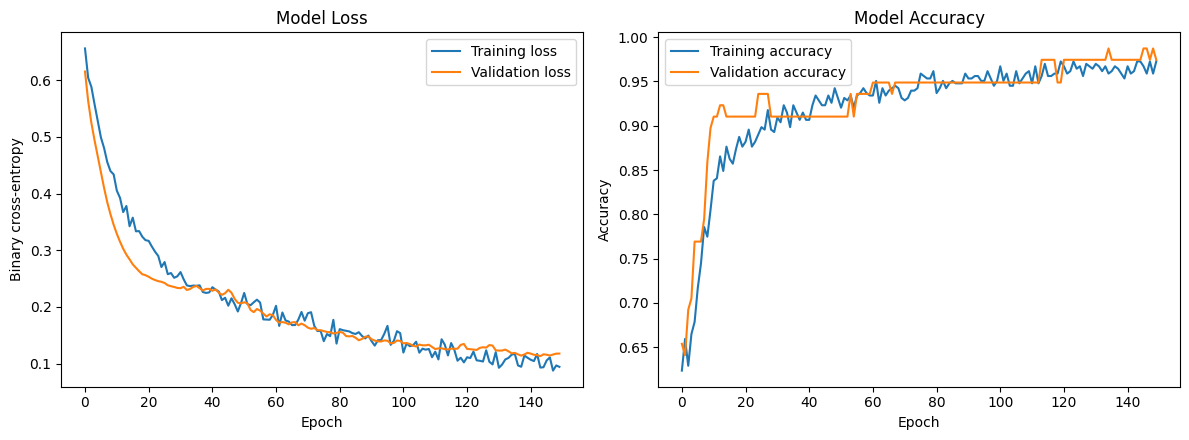

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
h = final_history.history

# Figure 4.1: loss and accuracy curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(h["loss"], label="Training loss")
ax[0].plot(h["val_loss"], label="Validation loss")
ax[0].set_title("Model Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Binary cross-entropy")
ax[0].legend()

ax[1].plot(h["accuracy"], label="Training accuracy")
ax[1].plot(h["val_accuracy"], label="Validation accuracy")
ax[1].set_title("Model Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()

plt.tight_layout()
plt.savefig("figure_4_1_curves.png", dpi=200)
plt.show()

files.download("figure_4_1_curves.png")

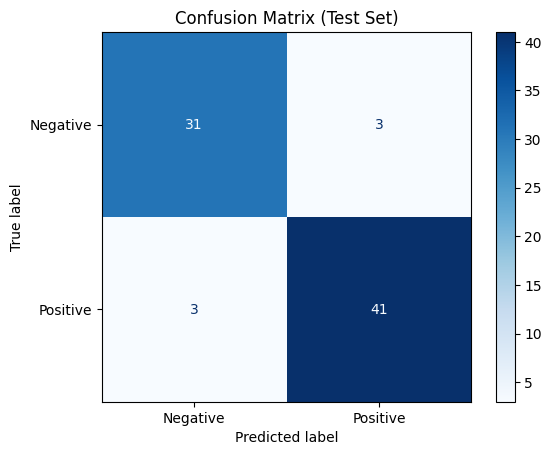

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
ConfusionMatrixDisplay(test_cm, display_labels=["Negative", "Positive"]).plot(cmap="Blues")
plt.title("Confusion Matrix (Test Set)")
plt.savefig("figure_4_2_confusion_matrix.png", dpi=200)
plt.show()

files.download("figure_4_2_confusion_matrix.png")